# Surface meshes from CAD

`mesh_cad_surface` triangulates the faces of a CAD model into one conforming surface mesh at a target edge size `h`, with no CAD kernel. The model is the B-rep a Kratos CAD JSON read keeps in `mesh.info["brep"]`, or a STEP or IGES read through OpenCASCADE.

- **Conforming.** Every B-rep edge is sampled once, by arc length, and its points are shared by every face that uses it, so the faces meet exactly and a closed solid comes out watertight.
- **Per face.** Each face is a constrained Delaunay triangulation of its parameter domain, mapped so that the triangulation follows the surface's own metric on average, filled with an equilateral lattice of step `h`, and lifted onto the surface. Every orientation and in-circle decision is one of Shewchuk's exact predicates.
- **Honest.** A face that cannot be meshed is left out and reported by index and reason, never meshed wrong; the report counts the open, non-manifold and misoriented edges, so a hole is always visible.
- **Deterministic.** The output is identical across parallel backends and thread counts.

It is also a CLI verb and an MCP tool: `meshioplusplus mesh-cad-surface part.cad.json part.vtu --size 0.1`. See `doc/mesh_cad.md`.

In [1]:
import os
import pathlib
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
    from vtkmodules.vtkCommonCore import vtkLogger
    vtkLogger.SetStderrVerbosity(vtkLogger.VERBOSITY_OFF)  # no X server: expected
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

REPO = pathlib.Path(os.getcwd()).parent.parent
CAD = REPO / 'tests' / 'python' / 'meshes' / 'cad_json'
DOC_IMAGES = REPO / 'doc' / 'public' / 'images'


def save_img(name, img=None):
    """Write a render (or the current matplotlib figure) to doc/public/images/<name>.png."""
    try:
        os.makedirs(DOC_IMAGES, exist_ok=True)
        path = DOC_IMAGES / (name + '.png')
        if img is None:
            plt.savefig(path, dpi=110, bbox_inches='tight')
        else:
            plt.imsave(path, img)
    except Exception as exc:  # pragma: no cover - read-only checkout
        print('doc image not written:', exc)


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')


def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def triangles(mesh):
    return np.asarray([c for c in mesh.cells if c.type == 'triangle'][0].data)


def render(meshes, titles, save, view=(25, 35), cmap='tab20'):
    """Surface meshes side by side, coloured by their source face (cad:face):
    PyVista when GL is available, else matplotlib 3-D collections."""
    n = len(meshes)
    if GL:
        pl = pv.Plotter(off_screen=True, shape=(1, n), window_size=(420 * n, 420), border=False)
        for k, (m, title) in enumerate(zip(meshes, titles)):
            pl.subplot(0, k)
            grid = to_pyvista(m).extract_cells_by_type(pv.CellType.TRIANGLE)
            pl.add_mesh(grid, scalars='cad:face', cmap=cmap, clim=(0, 19), show_edges=True,
                        edge_color='#222222', line_width=0.4, show_scalar_bar=False,
                        ambient=0.35, diffuse=0.65)
            pl.add_text(title, font_size=9)
            pl.camera.elevation, pl.camera.azimuth = view
            pl.reset_camera()
        img = pl.screenshot(return_img=True)
        pl.close()
        save_img(save, img)
        plt.figure(figsize=(4.2 * n, 4.2)); plt.imshow(img); plt.axis('off'); plt.show()
        return
    fig = plt.figure(figsize=(4.2 * n, 4.2))
    for k, (m, title) in enumerate(zip(meshes, titles)):
        ax = fig.add_subplot(1, n, k + 1, projection='3d')
        p, t = np.asarray(m.points), triangles(m)
        face = np.asarray(m.cell_data['cad:face'][0], dtype=float)
        colours = plt.get_cmap(cmap)((face % 20) / 19.0)
        ax.add_collection3d(Poly3DCollection(p[t], facecolors=colours, edgecolors='k', linewidths=0.15))
        lo, hi = p.min(axis=0), p.max(axis=0)
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        ax.set_box_aspect(hi - lo + 1e-9); ax.view_init(elev=view[0], azim=view[1])
        ax.set_axis_off(); ax.set_title(title, fontsize=9)
    save_img(save)
    plt.show()


def measure(mesh):
    """Area and enclosed volume (divergence theorem) of the triangles."""
    p, t = np.asarray(mesh.points), triangles(mesh)
    a, b, c = p[t[:, 0]], p[t[:, 1]], p[t[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(b - a, c - a), axis=1).sum()
    return area, np.einsum('ij,ij->i', a, np.cross(b, c)).sum() / 6.0


def show_report(report, keys):
    for k in keys:
        v = report[k]
        print(f'{k:24s} {v:.4g}' if isinstance(v, float) else f'{k:24s} {v}')
    for w in report['warnings']:
        print('warning:', w)

PyVista rendering


## Closed solids come out watertight

Three closed solids from the CAD JSON fixtures: a unit cube (six planar faces), a capped cylinder (its side is one periodic face cut open along a seam, which the edge sampler shares between the face's two sides) and a sphere (two hemispheres, each with two poles). The report's `num_open_edges`, `num_non_manifold_edges` and `num_misoriented_edges` are all zero: every triangle edge is used exactly twice, in opposite directions.

unit_cube:
num_faces                6
num_failed               0
num_points               194
num_triangles            384
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            23.79
max_edge                 0.2479
capped_cylinder:
num_faces                3
num_failed               0
num_points               600
num_triangles            1196
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            25.25
max_edge                 0.2813
sphere:
num_faces                2
num_failed               0
num_points               673
num_triangles            1342
num_open_edges           0
num_non_manifold_edges   0
num_misoriented_edges    0
min_angle_deg            10.16
max_edge                 0.2988


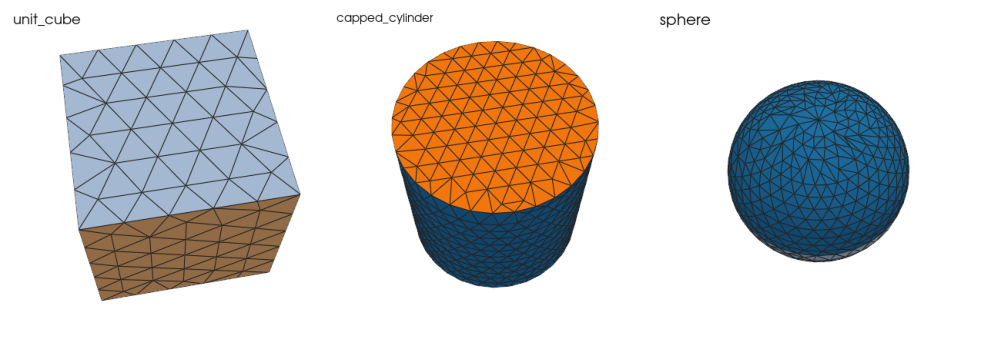

In [2]:
solids = {name: mp.read(CAD / f'{name}.cad.json') for name in ('unit_cube', 'capped_cylinder', 'sphere')}
surfaces = {}
for name, model in solids.items():
    surfaces[name], rep = mp.mesh_cad_surface(model, 0.2, return_report=True)
    print(f'{name}:')
    show_report(rep, ['num_faces', 'num_failed', 'num_points', 'num_triangles', 'num_open_edges',
                      'num_non_manifold_edges', 'num_misoriented_edges', 'min_angle_deg', 'max_edge'])
render(list(surfaces.values()), list(surfaces), 'mesh_cad_solids')

Area and enclosed volume converge at second order as `h` halves: the points lie on the exact surfaces (each sphere point at radius 1 to rounding), and the error is the chordal error of flat triangles.

In [3]:
exact = {'capped_cylinder': (6 * np.pi, 2 * np.pi), 'sphere': (4 * np.pi, 4 * np.pi / 3)}
for name, (area, volume) in exact.items():
    previous = None
    for h in (0.4, 0.2, 0.1, 0.05):
        out = mp.mesh_cad_surface(solids[name], h)
        a, v = measure(out)
        err = abs(a - area) / area
        rate = '' if previous is None else f'  ratio {previous / err:.2f}'
        print(f'{name:16s} h={h:<5} triangles {len(triangles(out)):6d}  area error {err:.2e}  '
              f'volume error {abs(v - volume) / volume:.2e}{rate}')
        previous = err
r = np.linalg.norm(mp.mesh_cad_surface(solids['sphere'], 0.1).points, axis=1)
print(f'sphere points: radius within {np.abs(r - 1).max():.1e} of 1')

capped_cylinder  h=0.4   triangles    292  area error 1.18e-02  volume error 2.00e-02
capped_cylinder  h=0.2   triangles   1196  area error 2.89e-03  volume error 4.69e-03  ratio 4.08
capped_cylinder  h=0.1   triangles   4748  area error 7.41e-04  volume error 1.16e-03  ratio 3.91
capped_cylinder  h=0.05  triangles  19034  area error 1.85e-04  volume error 2.86e-04  ratio 4.01
sphere           h=0.4   triangles    316  area error 2.09e-02  volume error 4.00e-02
sphere           h=0.2   triangles   1342  area error 4.76e-03  volume error 9.37e-03  ratio 4.39
sphere           h=0.1   triangles   5446  area error 1.12e-03  volume error 2.31e-03  ratio 4.26
sphere           h=0.05  triangles  22202  area error 2.52e-04  volume error 5.67e-04  ratio 4.44
sphere points: radius within 4.4e-16 of 1


## Trimmed faces follow their trims

The plate with a hole is one bilinear patch trimmed by an outer square and a circular hole. A CAD JSON read samples the patch on a lattice and keeps the cells whose centre is inside the trims, so its trimmed edges are staircases (left). `mesh_cad_surface` triangulates the trimmed domain itself, so the hole is a polygon inscribed in the circle (right), and `max_chordal_deviation` (OpenCASCADE's linear deflection) bounds how far its segments sit from the curve.

num_triangles            138
num_edge_segments        64
min_angle_deg            15.45
max_angle_deg            117.6
min_edge                 0.196
max_edge                 0.7406


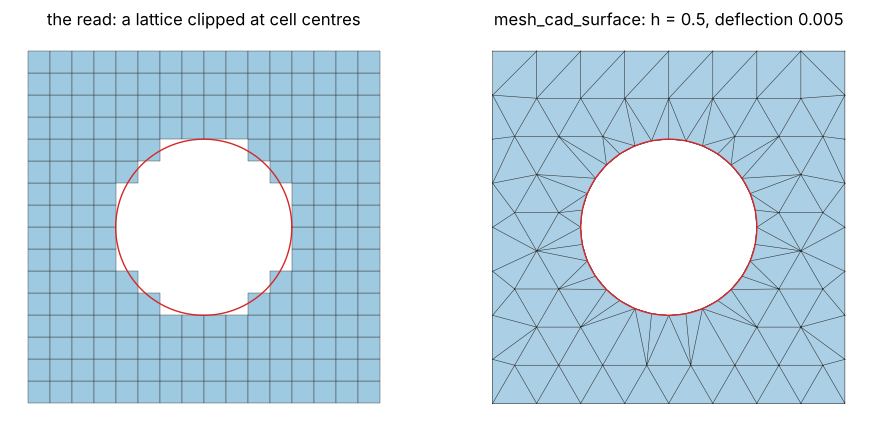

In [4]:
plate = mp.read(CAD / 'plate_with_hole.cad.json')
fine, rep = mp.mesh_cad_surface(plate, 0.5, max_chordal_deviation=0.005, return_report=True)
show_report(rep, ['num_triangles', 'num_edge_segments', 'min_angle_deg', 'max_angle_deg', 'min_edge', 'max_edge'])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
sampled = [c for c in plate.cells if c.type.startswith('quad')]
p = np.asarray(plate.points)
for block in sampled:
    for cell in np.asarray(block.data)[:, :4]:  # quad9: the corners
        q = p[np.r_[cell, cell[0]]]
        axes[0].fill(q[:, 0], q[:, 1], facecolor='#9ecae1', edgecolor='#333333', linewidth=0.3)
axes[0].set_title('the read: a lattice clipped at cell centres')
q = np.asarray(fine.points)
axes[1].tripcolor(q[:, 0], q[:, 1], triangles(fine), facecolors=np.ones(len(triangles(fine))),
                  cmap='Blues', vmin=0, vmax=3, edgecolors='none')
axes[1].triplot(q[:, 0], q[:, 1], triangles(fine), color='#333333', linewidth=0.4)
axes[1].set_title('mesh_cad_surface: h = 0.5, deflection 0.005')
t = np.linspace(0, 2 * np.pi, 400)
for ax in axes:
    ax.plot(2 + np.cos(t), 2 + np.sin(t), color='#d62728', linewidth=1.0)  # the hole
    ax.set_aspect('equal'); ax.set_axis_off()
save_img('mesh_cad_plate')
plt.show()

## Stretched parameters: the Scordelis–Lo roof

The roof is one untrimmed rational patch, an 80° arc of a cylinder of radius 25 by 50 long, whose parameter scales differ about fortyfold. A Delaunay triangulation in raw `(u, v)` would be fortyfold stretched on the surface. Each face is therefore triangulated after one affine map, the Cholesky factor of its mean first fundamental form, so the triangles are near-equilateral on the surface and the area converges to the exact `25 · 80° · 50`.

h=4.0  triangles   274  min angle  26.0  edges 2.09 to 5.51  area error 1.330
h=2.0  triangles  1088  min angle  28.9  edges 1.03 to 2.73  area error 0.327
h=1.0  triangles  4402  min angle  27.7  edges 0.50 to 1.43  area error 0.081


meshio warning [mesh_cad.cpp:587] mesh_cad_surface: face 0: its embedded edges are not meshed


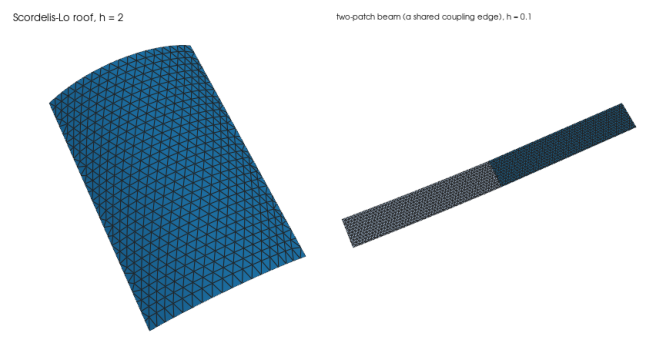

In [5]:
roof = mp.read(CAD / 'cylindrical_roof.cad.json')
exact_roof = 25.0 * np.radians(80.0) * 50.0
for h in (4.0, 2.0, 1.0):
    out, rep = mp.mesh_cad_surface(roof, h, return_report=True)
    print(f'h={h:<4} triangles {rep["num_triangles"]:5d}  min angle {rep["min_angle_deg"]:5.1f}  '
          f'edges {rep["min_edge"]:.2f} to {rep["max_edge"]:.2f}  area error {abs(measure(out)[0] - exact_roof):.3f}')
beam = mp.read(CAD / 'two_patch_beam.cad.json')
render([mp.mesh_cad_surface(roof, 2.0), mp.mesh_cad_surface(beam, 0.1)],
       ['Scordelis-Lo roof, h = 2', 'two-patch beam (a shared coupling edge), h = 0.1'],
       'mesh_cad_roof', view=(35, 20))

## A face that fails is reported, not meshed wrong

Corrupt one face of the cube (its patch index points nowhere). The face is left out and recorded with its status and reason; the open-edge count shows the hole; the other faces are unchanged. `strict=True` raises instead.

In [6]:
import copy

brep = copy.deepcopy(solids['unit_cube'].info['brep'])
brep['faces'][2]['patch'] = 99
broken, rep = mp.mesh_cad_surface(brep, 0.25, return_report=True)
print('failed faces:', rep['num_failed'], '- open edges:', rep['num_open_edges'])
for f in rep['faces']:
    if f['status'] != 'ok':
        print(f"face {f['face']}: {f['status']}: {f['reason']}")
try:
    mp.mesh_cad_surface(brep, 0.25, strict=True)
except RuntimeError as exc:
    print('strict:', exc)

failed faces: 1 - open edges: 16
face 2: unsupported: its patch index is out of range
strict: meshio++: mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range


meshio warning [mesh_cad.cpp:587] mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range
meshio warning [mesh_cad.cpp:587] mesh_cad_surface: face 2 is not meshed (unsupported): its patch index is out of range


## The planar triangulator

`triangulate_polygon_2d` is the constrained Delaunay triangulation underneath: a polygon with holes in the plane z = 0, either orientation, the even-odd rule deciding inside. With `target_size=0` it keeps the boundary as given; with `h > 0` it splits the boundary and fills the inside with a lattice.

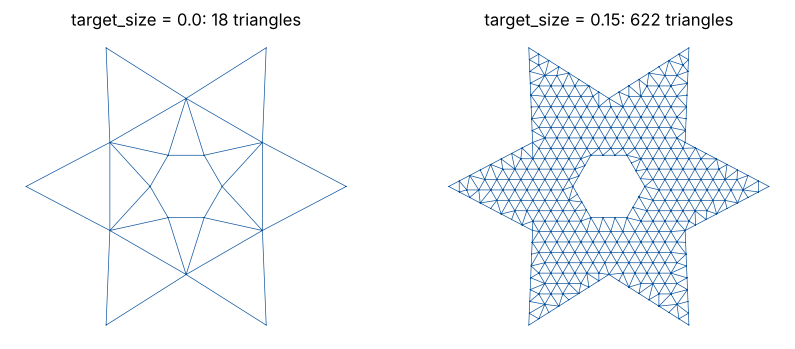

In [7]:
t = np.linspace(0, 2 * np.pi, 13)[:-1]
star = np.c_[np.cos(t), np.sin(t)] * np.where(np.arange(12) % 2, 0.55, 1.0)[:, None] * 2
hole = np.c_[0.45 * np.cos(-t[::2]), 0.45 * np.sin(-t[::2])]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, h in zip(axes, (0.0, 0.15)):
    m = mp.triangulate_polygon_2d(star, [hole], target_size=h)
    q = np.asarray(m.points)
    ax.triplot(q[:, 0], q[:, 1], np.asarray(m.cells[0].data), color='#08519c', linewidth=0.5)
    ax.set_title(f'target_size = {h}: {len(m.cells[0].data)} triangles')
    ax.set_aspect('equal'); ax.set_axis_off()
save_img('mesh_cad_polygon')
plt.show()

## A STEP solid, with OpenCASCADE

Where OpenCASCADE is linked, a STEP or IGES read carries the same B-rep, so `mesh_cad_surface` meshes it at a target size where the read's own `BRepMesh` triangulation is driven by deflection. The two agree on the area and enclosed volume of a box exactly.

In [8]:
if getattr(mp._core, '__has_occt__', False):
    path = os.path.join(tempfile.mkdtemp(), 'box.step')
    mp.write(path, mp.extract_surface(mp.box()))
    model = mp.read(path)
    ours, rep = mp.mesh_cad_surface(model, 0.1, return_report=True)
    print('BRepMesh:         triangles %5d  area %.12f  volume %.12f' % ((len(triangles(model)),) + measure(model)))
    print('mesh_cad_surface: triangles %5d  area %.12f  volume %.12f' % ((len(triangles(ours)),) + measure(ours)))
    print('open edges:', rep['num_open_edges'])
else:
    print('this build has no OpenCASCADE: STEP and IGES are not read')

BRepMesh:         triangles    12  area 6.000000000000  volume 1.000000000000
mesh_cad_surface: triangles  1488  area 6.000000000000  volume 1.000000000000
open edges: 0
